In [1]:
import pandas as pd
import numpy as np
import os
import glob
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Path to processed dataset folder
DATASET_PATH = "../dataset/processed"

# Find all CSV files
csv_files = glob.glob(os.path.join(DATASET_PATH, "*.csv"))

print("Number of CSV files found:", len(csv_files))

# Load and combine all datasets
dataframes = []

for file in csv_files:
    print("Loading:", os.path.basename(file))
    df = pd.read_csv(file, low_memory=False)
    dataframes.append(df)

data = pd.concat(dataframes, ignore_index=True)

print("\nDataset loaded successfully!")
print("Dataset shape:", data.shape)

Number of CSV files found: 8
Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Dataset loaded successfully!
Dataset shape: (2636670, 79)


In [3]:

# Check all attack categories
print("Unique attack categories:")
print(data["Label"].unique())

# Count records for each category
attack_counts = data["Label"].value_counts()

print("\nRecords per attack category:")
print(attack_counts)

# Check total number of classes
print("\nTotal number of classes:", data["Label"].nunique())

Unique attack categories:
<ArrowStringArray>
[                    'BENIGN',                       'DDoS',
                   'PortScan',                        'Bot',
               'Infiltration',   'Web Attack � Brute Force',
           'Web Attack � XSS', 'Web Attack � Sql Injection',
                'FTP-Patator',                'SSH-Patator',
              'DoS slowloris',           'DoS Slowhttptest',
                   'DoS Hulk',              'DoS GoldenEye',
                 'Heartbleed']
Length: 15, dtype: str

Records per attack category:
Label
BENIGN                        2185138
DoS Hulk                       174334
DDoS                           128021
PortScan                       114652
DoS GoldenEye                   10286
FTP-Patator                      5935
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3545
Bot                              1956
Web Attack � Brute Force         1470
Web Attack � XSS    

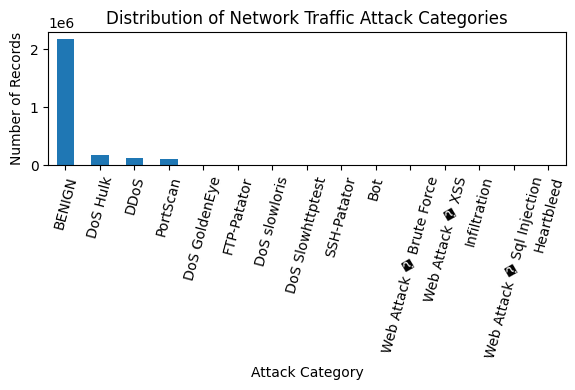

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

attack_counts.plot(kind="bar")

plt.title("Distribution of Network Traffic Attack Categories")
plt.xlabel("Attack Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [8]:
# Clean spaces and normalize Web Attack labels

data["Label"] = data["Label"].astype(str).str.strip()

data["Label"] = data["Label"].str.replace(
    "�", "-", regex=False
)

print("Cleaned attack categories:")
print(data["Label"].unique())

print("\nUpdated class distribution:")
print(data["Label"].value_counts())

Cleaned attack categories:
<ArrowStringArray>
[                    'BENIGN',                       'DDoS',
                   'PortScan',                        'Bot',
               'Infiltration',   'Web Attack - Brute Force',
           'Web Attack - XSS', 'Web Attack - Sql Injection',
                'FTP-Patator',                'SSH-Patator',
              'DoS slowloris',           'DoS Slowhttptest',
                   'DoS Hulk',              'DoS GoldenEye',
                 'Heartbleed']
Length: 15, dtype: str

Updated class distribution:
Label
BENIGN                        2185138
DoS Hulk                       174334
DDoS                           128021
PortScan                       114652
DoS GoldenEye                   10286
FTP-Patator                      5935
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3545
Bot                              1956
Web Attack - Brute Force         1470
Web Attack - XSS    

In [9]:
# Identify classes with fewer than 100 records

rare_classes = data["Label"].value_counts()

print("Rare attack categories:")
print(rare_classes[rare_classes < 100])

Rare attack categories:
Label
Infiltration                  36
Web Attack - Sql Injection    21
Heartbleed                    11
Name: count, dtype: int64


In [10]:
# Create a copy of the dataset
df = data.copy()

# Remove duplicate records
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
after = len(df)

print("Original records:", before)
print("Records after removing duplicates:", after)
print("Duplicates removed:", before - after)

# Separate features and target
X = df.drop(columns=["Label"])
y = df["Label"]

# Convert features to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with NaN
X = X.replace([np.inf, -np.inf], np.nan)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values:", X.isna().sum().sum())
print("Number of classes:", y.nunique())

Original records: 2636670
Records after removing duplicates: 2522362
Duplicates removed: 114308

Feature shape: (2522362, 78)
Target shape: (2522362,)

Missing values: 3128
Number of classes: 15


In [11]:

# Check class distribution after preprocessing

class_counts = y.value_counts()

distribution = pd.DataFrame({
    "Attack_Category": class_counts.index,
    "Record_Count": class_counts.values,
    "Percentage": (
        class_counts.values / len(y) * 100
    ).round(4)
})

print(distribution.to_string(index=False))

print("\nTotal records:", len(y))
print("Total classes:", y.nunique())

           Attack_Category  Record_Count  Percentage
                    BENIGN       2096484     83.1159
                  DoS Hulk        172849      6.8527
                      DDoS        128016      5.0752
                  PortScan         90819      3.6006
             DoS GoldenEye         10286      0.4078
               FTP-Patator          5933      0.2352
             DoS slowloris          5385      0.2135
          DoS Slowhttptest          5228      0.2073
               SSH-Patator          3219      0.1276
                       Bot          1953      0.0774
  Web Attack - Brute Force          1470      0.0583
          Web Attack - XSS           652      0.0258
              Infiltration            36      0.0014
Web Attack - Sql Injection            21      0.0008
                Heartbleed            11      0.0004

Total records: 2522362
Total classes: 15


In [12]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nTraining classes:", y_train.nunique())
print("Testing classes:", y_test.nunique())

Training data shape: (2017889, 78)
Testing data shape: (504473, 78)

Training class distribution:
Label
BENIGN                        1677187
DoS Hulk                       138279
DDoS                           102413
PortScan                        72655
DoS GoldenEye                    8229
FTP-Patator                      4746
DoS slowloris                    4308
DoS Slowhttptest                 4182
SSH-Patator                      2575
Bot                              1562
Web Attack - Brute Force         1176
Web Attack - XSS                  522
Infiltration                       29
Web Attack - Sql Injection         17
Heartbleed                          9
Name: count, dtype: int64

Testing class distribution:
Label
BENIGN                        419297
DoS Hulk                       34570
DDoS                           25603
PortScan                       18164
DoS GoldenEye                   2057
FTP-Patator                     1187
DoS slowloris                   1077
DoS Sl

In [13]:
rare_labels = [
    "Infiltration",
    "Web Attack - Sql Injection",
    "Heartbleed"
]

for label in rare_labels:
    print(f"\n{label}")
    print("Training:", (y_train == label).sum())
    print("Testing:", (y_test == label).sum())


Infiltration
Training: 29
Testing: 7

Web Attack - Sql Injection
Training: 17
Testing: 4

Heartbleed
Training: 9
Testing: 2


In [15]:
import gc
import numpy as np

# Convert numerical features to float32
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

# Replace infinite values with NaN
X_train.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove columns that are entirely missing in training
valid_columns = X_train.columns[X_train.notna().any()]

X_train = X_train[valid_columns]
X_test = X_test[valid_columns]

gc.collect()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training data type:", X_train.dtypes.unique())
print("Missing values:", X_train.isna().sum().sum())
print("Number of classes:", y_train.nunique())

Training shape: (2017889, 78)
Testing shape: (504473, 78)
Training data type: [dtype('float32')]
Missing values: 2528
Number of classes: 15


In [16]:
from lightgbm import LGBMClassifier
import time

# Create multiclass LightGBM model
multiclass_model = LGBMClassifier(
    objective="multiclass",
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

# Train model
start_time = time.time()

multiclass_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Multiclass model training completed!")
print("Training time:", round(training_time, 2), "seconds")
print("Number of classes:", len(multiclass_model.classes_))
print("Classes:", multiclass_model.classes_)

Multiclass model training completed!
Training time: 312.8 seconds
Number of classes: 15
Classes: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - Sql Injection'
 'Web Attack - XSS']


In [17]:
from sklearn.metrics import accuracy_score, classification_report
import time

# Predict attack categories on test data
start_time = time.time()

y_pred = multiclass_model.predict(X_test)

prediction_time = time.time() - start_time

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Prediction time:", round(prediction_time, 2), "seconds")

# Detailed performance for all 15 categories
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

MODEL EVALUATION RESULTS
------------------------
Accuracy: 96.2 %
Prediction time: 33.83 seconds

CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN       0.98      0.99      0.98    419297
                       Bot       0.00      0.00      0.00       391
                      DDoS       0.93      0.88      0.90     25603
             DoS GoldenEye       0.21      0.09      0.12      2057
                  DoS Hulk       0.92      0.89      0.90     34570
          DoS Slowhttptest       0.26      0.56      0.35      1046
             DoS slowloris       0.29      0.33      0.31      1077
               FTP-Patator       0.44      0.08      0.13      1187
                Heartbleed       0.00      0.00      0.00         2
              Infiltration       0.00      0.00      0.00         7
                  PortScan       0.96      0.86      0.91     18164
               SSH-Patator       0.58      0.22      0.32     

In [18]:
# Keep 11 important categories

selected_classes = [
    "BENIGN",
    "DDoS",
    "PortScan",
    "DoS Hulk",
    "DoS GoldenEye",
    "FTP-Patator",
    "DoS slowloris",
    "DoS Slowhttptest",
    "SSH-Patator",
    "Bot",
    "Web Attack - Brute Force"
]

# Filter existing training and testing data
train_mask = y_train.isin(selected_classes)
test_mask = y_test.isin(selected_classes)

X_train_final = X_train.loc[train_mask]
y_train_final = y_train.loc[train_mask]

X_test_final = X_test.loc[test_mask]
y_test_final = y_test.loc[test_mask]

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

print("\nTraining class distribution:")
print(y_train_final.value_counts())

print("\nTesting class distribution:")
print(y_test_final.value_counts())

print("\nNumber of classes:", y_train_final.nunique())

Final training shape: (2017312, 78)
Final testing shape: (504330, 78)

Training class distribution:
Label
BENIGN                      1677187
DoS Hulk                     138279
DDoS                         102413
PortScan                      72655
DoS GoldenEye                  8229
FTP-Patator                    4746
DoS slowloris                  4308
DoS Slowhttptest               4182
SSH-Patator                    2575
Bot                            1562
Web Attack - Brute Force       1176
Name: count, dtype: int64

Testing class distribution:
Label
BENIGN                      419297
DoS Hulk                     34570
DDoS                         25603
PortScan                     18164
DoS GoldenEye                 2057
FTP-Patator                   1187
DoS slowloris                 1077
DoS Slowhttptest              1046
SSH-Patator                    644
Bot                            391
Web Attack - Brute Force       294
Name: count, dtype: int64

Number of classes: 11


In [19]:
from lightgbm import LGBMClassifier
from collections import Counter
import time

# Calculate class weights
class_counts = Counter(y_train_final)

class_weights = {
    label: min(
        len(y_train_final) / (len(class_counts) * count),
        20
    )
    for label, count in class_counts.items()
}

# Create final model
final_model = LGBMClassifier(
    objective="multiclass",
    n_estimators=250,
    learning_rate=0.05,
    num_leaves=31,
    class_weight=class_weights,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

# Train model
start_time = time.time()

final_model.fit(X_train_final, y_train_final)

training_time = time.time() - start_time

print("FINAL MULTICLASS MODEL TRAINED SUCCESSFULLY!")
print("Training time:", round(training_time, 2), "seconds")
print("Number of classes:", len(final_model.classes_))
print("Classes:", final_model.classes_)

FINAL MULTICLASS MODEL TRAINED SUCCESSFULLY!
Training time: 393.16 seconds
Number of classes: 11
Classes: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'PortScan' 'SSH-Patator'
 'Web Attack - Brute Force']


In [20]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import time

# Generate predictions
start_time = time.time()

y_pred_final = final_model.predict(X_test_final)

prediction_time = time.time() - start_time

# Calculate accuracy
accuracy = accuracy_score(y_test_final, y_pred_final)

print("FINAL MODEL EVALUATION")
print("----------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Prediction time:", round(prediction_time, 2), "seconds")

# Classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_final,
    y_pred_final,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test_final,
    y_pred_final,
    labels=final_model.classes_
)

print("Confusion Matrix Shape:", cm.shape)


FINAL MODEL EVALUATION
----------------------
Accuracy: 99.9 %
Prediction time: 31.55 seconds

CLASSIFICATION REPORT
                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00    419297
                     Bot       0.71      0.97      0.82       391
                    DDoS       1.00      1.00      1.00     25603
           DoS GoldenEye       0.99      1.00      0.99      2057
                DoS Hulk       1.00      1.00      1.00     34570
        DoS Slowhttptest       0.98      0.99      0.99      1046
           DoS slowloris       1.00      0.99      1.00      1077
             FTP-Patator       1.00      1.00      1.00      1187
                PortScan       0.99      1.00      0.99     18164
             SSH-Patator       1.00      1.00      1.00       644
Web Attack - Brute Force       0.99      0.99      0.99       294

                accuracy                           1.00    504330
               macro av

In [21]:
import pandas as pd
import os

for file in csv_files:

    labels = pd.read_csv(
        file,
        usecols=["Label"],
        low_memory=False
    )

    labels["Label"] = (
        labels["Label"]
        .astype(str)
        .str.strip()
        .str.replace("�", "-", regex=False)
    )

    print("\nFile:", os.path.basename(file))

    print(
        labels["Label"]
        .value_counts()
        .to_string()
    )


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Label
DDoS      128021
BENIGN     95854

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Label
BENIGN      124040
PortScan    114652

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Label
BENIGN    183673
Bot         1956

File: Monday-WorkingHours.pcap_ISCX.csv
Label
BENIGN    512438

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Label
BENIGN          260462
Infiltration        36

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Label
BENIGN                        163394
Web Attack - Brute Force        1470
Web Attack - XSS                 652
Web Attack - Sql Injection        21

File: Tuesday-WorkingHours.pcap_ISCX.csv
Label
BENIGN         419782
FTP-Patator      5935
SSH-Patator      3545

File: Wednesday-workingHours.pcap_ISCX.csv
Label
BENIGN              425495
DoS Hulk            174334
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Heartbleed   

In [22]:
import pandas as pd
import os

summary = []

for file in csv_files:

    labels = pd.read_csv(
        file,
        usecols=["Label"],
        low_memory=False
    )

    labels["Label"] = (
        labels["Label"]
        .astype(str)
        .str.strip()
        .str.replace("�", "-", regex=False)
    )

    counts = labels["Label"].value_counts()

    row = {"File": os.path.basename(file)}

    for category in selected_classes:
        row[category] = counts.get(category, 0)

    summary.append(row)

attack_summary = pd.DataFrame(summary)

display(attack_summary)

,File,BENIGN,DDoS,PortScan,DoS Hulk,DoS GoldenEye,FTP-Patator,DoS slowloris,DoS Slowhttptest,SSH-Patator,Bot,Web Attack - Brute Force
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,95854,128021,0,0,0,0,0,0,0,0,0
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,124040,0,114652,0,0,0,0,0,0,0,0
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,183673,0,0,0,0,0,0,0,0,1956,0
3,Monday-WorkingHours.pcap_ISCX.csv,512438,0,0,0,0,0,0,0,0,0,0
4,Thursday-WorkingHours-Afternoon-Infilteration....,260462,0,0,0,0,0,0,0,0,0,0
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,163394,0,0,0,0,0,0,0,0,0,1470
6,Tuesday-WorkingHours.pcap_ISCX.csv,419782,0,0,0,0,5935,0,0,3545,0,0
7,Wednesday-workingHours.pcap_ISCX.csv,425495,0,0,174334,10286,0,5385,5228,0,0,0


In [23]:
wednesday_file = [
    file for file in csv_files
    if "Wednesday" in os.path.basename(file)
][0]

print("Unseen test file:")
print(wednesday_file)

Unseen test file:
../dataset/processed\Wednesday-workingHours.pcap_ISCX.csv


In [24]:
import pandas as pd
import numpy as np
import os
import gc

# Load Wednesday as unseen test data
test_df = pd.read_csv(
    wednesday_file,
    low_memory=False
)

# Load remaining 7 files as training data
train_files = [
    file for file in csv_files
    if "Wednesday" not in os.path.basename(file)
]

train_data = pd.concat(
    [pd.read_csv(file, low_memory=False) for file in train_files],
    ignore_index=True
)

# Clean labels
for dataset in [train_data, test_df]:
    dataset["Label"] = (
        dataset["Label"]
        .astype(str)
        .str.strip()
        .str.replace("�", "-", regex=False)
    )

# Keep selected categories
train_data = train_data[
    train_data["Label"].isin(selected_classes)
].copy()

test_df = test_df[
    test_df["Label"].isin(selected_classes)
].copy()

# Prepare features and target
X_train_day = train_data.drop(columns=["Label"])
y_train_day = train_data["Label"]

X_test_day = test_df.drop(columns=["Label"])
y_test_day = test_df["Label"]

# Match the feature columns
X_test_day = X_test_day.reindex(
    columns=X_train_day.columns
)

# Convert to float32
X_train_day = X_train_day.apply(
    pd.to_numeric, errors="coerce"
).astype(np.float32)

X_test_day = X_test_day.apply(
    pd.to_numeric, errors="coerce"
).astype(np.float32)

# Replace infinite values
X_train_day.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test_day.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Training shape:", X_train_day.shape)
print("Unseen Wednesday testing shape:", X_test_day.shape)

print("\nTraining categories:")
print(y_train_day.value_counts())

print("\nWednesday testing categories:")
print(y_test_day.value_counts())

Training shape: (2015222, 78)
Unseen Wednesday testing shape: (620728, 78)

Training categories:
Label
BENIGN                      1759643
DDoS                         128021
PortScan                     114652
FTP-Patator                    5935
SSH-Patator                    3545
Bot                            1956
Web Attack - Brute Force       1470
Name: count, dtype: int64

Wednesday testing categories:
Label
BENIGN              425495
DoS Hulk            174334
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Name: count, dtype: int64


In [25]:
from lightgbm import LGBMClassifier
import time

# Identify classes available in training
day_classes = sorted(y_train_day.unique())

print("Training classes:", day_classes)

# Train separate validation model
day_model = LGBMClassifier(
    objective="multiclass",
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

start_time = time.time()

day_model.fit(X_train_day, y_train_day)

print("\nUnseen-day validation model trained!")
print("Training time:", round(time.time() - start_time, 2), "seconds")
print("Learned classes:", day_model.classes_)

Training classes: ['BENIGN', 'Bot', 'DDoS', 'FTP-Patator', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force']

Unseen-day validation model trained!
Training time: 143.87 seconds
Learned classes: ['BENIGN' 'Bot' 'DDoS' 'FTP-Patator' 'PortScan' 'SSH-Patator'
 'Web Attack - Brute Force']


In [26]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred_day = day_model.predict(X_test_day)

print("Wednesday Closed-Set Accuracy:",
      round(accuracy_score(y_test_day, y_pred_day), 4))

print("\nClassification Report:")
print(classification_report(
    y_test_day,
    y_pred_day,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_day,
    y_pred_day,
    labels=day_model.classes_
))

Wednesday Closed-Set Accuracy: 0.6844

Classification Report:
                          precision    recall  f1-score   support

                  BENIGN       0.69      1.00      0.82    425495
                     Bot       0.00      0.00      0.00         0
                    DDoS       0.00      0.00      0.00         0
           DoS GoldenEye       0.00      0.00      0.00     10286
                DoS Hulk       0.00      0.00      0.00    174334
        DoS Slowhttptest       0.00      0.00      0.00      5228
           DoS slowloris       0.00      0.00      0.00      5385
             FTP-Patator       0.00      0.00      0.00         0
                PortScan       0.00      0.00      0.00         0
             SSH-Patator       0.00      0.00      0.00         0
Web Attack - Brute Force       0.00      0.00      0.00         0

                accuracy                           0.68    620728
               macro avg       0.06      0.09      0.07    620728
            

In [27]:
# Select only normal network traffic
benign_data = train_data[
    train_data["Label"] == "BENIGN"
].copy()

# Separate features
X_benign = benign_data.drop(columns=["Label"])

# Convert features to numeric
X_benign = X_benign.apply(
    pd.to_numeric, errors="coerce"
).astype(np.float32)

# Replace infinite values
X_benign.replace(
    [np.inf, -np.inf], np.nan, inplace=True
)

# Remove rows containing missing values
X_benign.dropna(inplace=True)

print("BENIGN training data shape:", X_benign.shape)
print("\nMissing values:", X_benign.isna().sum().sum())

BENIGN training data shape: (1758417, 78)

Missing values: 0


In [28]:
# Create a sample of normal traffic
X_benign_sample = X_benign.sample(
    n=100000,
    random_state=42
)

print("Sample training shape:", X_benign_sample.shape)

Sample training shape: (100000, 78)


In [29]:
from sklearn.ensemble import IsolationForest
import time

isolation_model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=4
)

start_time = time.time()

isolation_model.fit(X_benign_sample)

training_time = time.time() - start_time

print("Isolation Forest training completed!")
print("Training time:", round(training_time, 2), "seconds")
print("Training records:", len(X_benign_sample))

Isolation Forest training completed!
Training time: 0.48 seconds
Training records: 100000


In [30]:
# Separate actual labels from Wednesday traffic
y_wednesday_actual = test_df["Label"].copy()

# Prepare Wednesday features
X_wednesday = test_df.drop(columns=["Label"])

X_wednesday = X_wednesday.reindex(
    columns=X_benign_sample.columns
)

X_wednesday = X_wednesday.apply(
    pd.to_numeric, errors="coerce"
).astype(np.float32)

X_wednesday.replace(
    [np.inf, -np.inf], np.nan, inplace=True
)

# Remove rows with missing values
valid_rows = X_wednesday.notna().all(axis=1)

X_wednesday = X_wednesday.loc[valid_rows]
y_wednesday_actual = y_wednesday_actual.loc[valid_rows]

print("Wednesday testing shape:", X_wednesday.shape)
print("Actual labels shape:", y_wednesday_actual.shape)
print("\nActual traffic distribution:")
print(y_wednesday_actual.value_counts())

Wednesday testing shape: (620404, 78)
Actual labels shape: (620404,)

Actual traffic distribution:
Label
BENIGN              425181
DoS Hulk            174324
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Name: count, dtype: int64


In [31]:
# Predict normal and anomalous traffic
anomaly_predictions = isolation_model.predict(X_wednesday)

# Convert predictions into readable labels
anomaly_results = pd.Series(
    anomaly_predictions
).map({
    1: "Normal",
    -1: "Anomaly"
})

print("Anomaly detection completed!")

print("\nPrediction distribution:")
print(anomaly_results.value_counts())

print("\nPrediction percentages:")
print(
    anomaly_results.value_counts(normalize=True).mul(100).round(2)
)

Anomaly detection completed!

Prediction distribution:
Normal     415913
Anomaly    204491
Name: count, dtype: int64

Prediction percentages:
Normal     67.04
Anomaly    32.96
Name: proportion, dtype: float64


In [32]:
from sklearn.metrics import classification_report, confusion_matrix

# Convert actual labels into binary values
y_actual_binary = (
    y_wednesday_actual != "BENIGN"
).astype(int)

# Convert Isolation Forest predictions
y_pred_binary = (
    anomaly_predictions == -1
).astype(int)

print("Anomaly Detection Classification Report:\n")

print(classification_report(
    y_actual_binary,
    y_pred_binary,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_actual_binary,
    y_pred_binary
))

Anomaly Detection Classification Report:

              precision    recall  f1-score   support

      BENIGN       0.94      0.92      0.93    425181
      ATTACK       0.83      0.87      0.85    195223

    accuracy                           0.90    620404
   macro avg       0.88      0.89      0.89    620404
weighted avg       0.90      0.90      0.90    620404

Confusion Matrix:
[[389978  35203]
 [ 25935 169288]]


In [33]:

import pandas as pd

results_df = pd.DataFrame({
    "Actual_Label": y_wednesday_actual.values,
    "Prediction": anomaly_predictions
})

results_df["Detection"] = results_df["Prediction"].map({
    1: "Normal",
    -1: "Anomaly"
})

class_results = results_df.groupby("Actual_Label").agg(
    Total_Records=("Detection", "count"),
    Detected_Anomalies=("Detection", lambda x: (x == "Anomaly").sum())
)

class_results["Detection_Rate_%"] = (
    class_results["Detected_Anomalies"] /
    class_results["Total_Records"] * 100
).round(2)

print(class_results)

                  Total_Records  Detected_Anomalies  Detection_Rate_%
Actual_Label                                                         
BENIGN                   425181               35203              8.28
DoS GoldenEye             10286                6509             63.28
DoS Hulk                 174324              155499             89.20
DoS Slowhttptest           5228                4176             79.88
DoS slowloris              5385                3104             57.64


In [34]:
import joblib
import os

# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Prepare model artifact
isolation_artifact = {
    "model": isolation_model,
    "feature_columns": list(X_benign_sample.columns),
    "model_name": "Isolation Forest",
    "training_samples": len(X_benign_sample)
}

# Save model
model_path = "../models/cyberattack_isolation_forest.joblib"

joblib.dump(isolation_artifact, model_path)

print("Isolation Forest model saved successfully!")
print("Location:", model_path)

Isolation Forest model saved successfully!
Location: ../models/cyberattack_isolation_forest.joblib


In [35]:
import joblib

# Load saved model
loaded_artifact = joblib.load(
    "../models/cyberattack_isolation_forest.joblib"
)

loaded_model = loaded_artifact["model"]

# Test on 10 Wednesday records
sample_predictions = loaded_model.predict(
    X_wednesday.iloc[:10]
)

print("Model loaded successfully!")
print("Number of features:",
      len(loaded_artifact["feature_columns"]))

print("\nSample predictions:")
for i, prediction in enumerate(sample_predictions):
    result = "Normal" if prediction == 1 else "Anomaly"
    print(f"Record {i+1}: {result}")

Model loaded successfully!
Number of features: 78

Sample predictions:
Record 1: Normal
Record 2: Normal
Record 3: Normal
Record 4: Normal
Record 5: Normal
Record 6: Normal
Record 7: Normal
Record 8: Anomaly
Record 9: Normal
Record 10: Normal


In [36]:
import os

# Create results folder
os.makedirs("../results", exist_ok=True)

# Save attack-wise detection results
class_results.to_csv(
    "../results/isolation_forest_class_results.csv"
)

# Save overall classification report
from sklearn.metrics import classification_report

report = classification_report(
    y_actual_binary,
    y_pred_binary,
    target_names=["BENIGN", "ATTACK"],
    output_dict=True
)

pd.DataFrame(report).transpose().to_csv(
    "../results/isolation_forest_evaluation.csv"
)

print("Evaluation results saved successfully!")
print("1. isolation_forest_class_results.csv")
print("2. isolation_forest_evaluation.csv")

Evaluation results saved successfully!
1. isolation_forest_class_results.csv
2. isolation_forest_evaluation.csv


In [37]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

multiclass_artifact = {
    "model": final_model,
    "feature_columns": list(X_train_final.columns),
    "classes": list(final_model.classes_)
}

joblib.dump(
    multiclass_artifact,
    "../models/cyberattack_multiclass_lightgbm_model.joblib"
)

print("Multiclass LightGBM model saved successfully!")

Multiclass LightGBM model saved successfully!


In [38]:
print("X_test_final exists:", "X_test_final" in globals())
print("y_test_final exists:", "y_test_final" in globals())

print("\nAvailable testing variables:")
print([name for name in globals() if "test" in name.lower()])

X_test_final exists: True
y_test_final exists: True

Available testing variables:
['train_test_split', 'X_test', 'y_test', 'test_mask', 'X_test_final', 'y_test_final', 'test_df', 'X_test_day', 'y_test_day']


In [39]:
# Check testing dataset size
print("Testing dataset shape:", X_test_final.shape)

# Check available categories and their record counts
print("\nTesting dataset class distribution:")
print(y_test_final.value_counts())

Testing dataset shape: (504330, 78)

Testing dataset class distribution:
Label
BENIGN                      419297
DoS Hulk                     34570
DDoS                         25603
PortScan                     18164
DoS GoldenEye                 2057
FTP-Patator                   1187
DoS slowloris                 1077
DoS Slowhttptest              1046
SSH-Patator                    644
Bot                            391
Web Attack - Brute Force       294
Name: count, dtype: int64


In [40]:
import pandas as pd
from pathlib import Path

# Number of records to select from each category
sample_counts = {
    "BENIGN": 200,
    "DDoS": 100,
    "PortScan": 100,
    "DoS Hulk": 100,
    "DoS GoldenEye": 100,
    "FTP-Patator": 100,
    "DoS slowloris": 100,
    "DoS Slowhttptest": 100,
    "SSH-Patator": 100,
    "Bot": 100,
    "Web Attack - Brute Force": 100
}

# Combine testing features and original labels
test_data = X_test_final.copy()
test_data["Label"] = y_test_final

# Select balanced records
sample_list = []

for attack, count in sample_counts.items():
    category_data = test_data[test_data["Label"] == attack]

    selected = category_data.sample(
        n=count,
        random_state=42
    )

    sample_list.append(selected)

# Combine and shuffle records
sample_df = pd.concat(sample_list, ignore_index=True)
sample_df = sample_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Find project folder and save CSV
project_dir = Path.cwd()

if not (project_dir / "dataset").exists():
    project_dir = project_dir.parent

output_folder = project_dir / "dataset" / "processed"
output_folder.mkdir(parents=True, exist_ok=True)

output_path = output_folder / "CyberShield_Sample_Test.csv"

sample_df.to_csv(output_path, index=False)

# Display results
print("Sample dataset created successfully!")
print("Total records:", len(sample_df))
print("Total columns:", len(sample_df.columns))
print("\nClass distribution:")
print(sample_df["Label"].value_counts())
print("\nSaved at:", output_path)

Sample dataset created successfully!
Total records: 1200
Total columns: 79

Class distribution:
Label
BENIGN                      200
Web Attack - Brute Force    100
DoS Slowhttptest            100
DoS Hulk                    100
PortScan                    100
SSH-Patator                 100
DDoS                        100
DoS GoldenEye               100
DoS slowloris               100
FTP-Patator                 100
Bot                         100
Name: count, dtype: int64

Saved at: c:\Users\Swapnil\OneDrive\Desktop\ML project\dataset\processed\CyberShield_Sample_Test.csv
